# Custom Species, Kinetics & Reaction Mechanisms (`softpotato.reactions`)

## 1. Goal

Construct custom chemical `Species`, interfacial `ElectrochemicalStep`s, and homogeneous `FirstOrderReaction` / `SecondOrderReaction` networks inside `CustomMechanism`, then solve the coupled reaction–diffusion PDE using `Mechanism.create_problem()` and `get_solver("scipy_ivp")`.

## 2. Example A: First-Order EC Mechanism ($\text{Ox} + e^- \rightleftharpoons \text{Red}$, $\text{Red} \xrightarrow{k_1} \text{P}$)

We define three `Species`, a `ButlerVolmer` `ElectrochemicalStep`, and a `FirstOrderReaction` in `CustomMechanism`, and inspect how the homogeneous rate constant $k_1$ shifts the cyclic voltammogram.

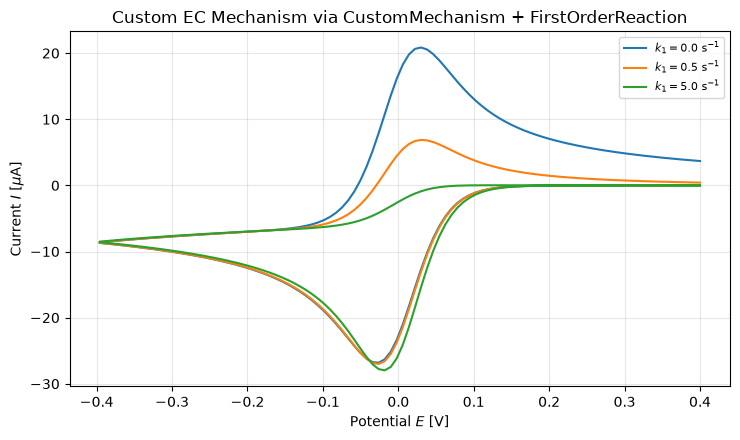

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato.geometry import PlanarGeometry
from softpotato.grid import GeometricExpandingMesh
from softpotato.reactions import (
    ButlerVolmer,
    CustomMechanism,
    ElectrochemicalStep,
    FirstOrderReaction,
    SecondOrderReaction,
    Species,
)
from softpotato.solver import get_solver

D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
E_start, E_vertex, scan_rate = 0.4, -0.4, 0.2
t_total = 2.0 * abs(E_vertex - E_start) / scan_rate
t_half = abs(E_vertex - E_start) / scan_rate
def potential_fn(t: float) -> float:
    return E_start - scan_rate * t if t <= t_half else E_vertex + scan_rate * (t - t_half)
t_eval = np.linspace(0.0, t_total, 200)

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=0.0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
prod = Species("P", diffusivity=D, bulk_concentration=0.0)

mesh = GeometricExpandingMesh.from_diffusion_layer(D=D, t_max=t_total, n_points=70, gamma=1.08)
geom = PlanarGeometry(area=area)
solver = get_solver("scipy_ivp", method="BDF", rtol=1e-6, atol=1e-9)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k1 in [0.0, 0.5, 5.0]:
    reactions = [FirstOrderReaction(red, prod, k=k1)] if k1 > 0 else []
    mech = CustomMechanism(
        species=[ox, red, prod],
        reactions=reactions,
        electrochemical_steps=[
            ElectrochemicalStep(ox, red, ButlerVolmer(k0=1e-2, alpha=0.5, E0=0.0, n=1))
        ],
        name=f"EC (k1={k1})",
    )
    prob = mech.create_problem(mesh, potential=potential_fn, geometry=geom)
    res = solver.solve(prob, t_span=(0.0, t_total), t_eval=t_eval)
    E_arr = np.array([potential_fn(ti) for ti in t_eval])
    ax.plot(E_arr, res.currents["Ox"] * 1e6, label=rf"$k_1 = {k1}\ \mathrm{{s}}^{{-1}}$")

ax.set_xlabel("Potential $E$ [V]")
ax.set_ylabel(r"Current $I$ [$\mu$A]")
ax.set_title("Custom EC Mechanism via CustomMechanism + FirstOrderReaction")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 3. Example B: Second-Order Homogeneous Reaction ($\text{Red} + \text{Z} \xrightarrow{k_2} \text{P}$)

`SecondOrderReaction(reactant_1, reactant_2, product, k)` automatically provides both the nonlinear rate law $r = k_2 c_{\text{Red}} c_{\text{Z}}$ and its exact analytical local Jacobian to `scipy_ivp` (BDF/Radau). Here we simulate a potential step generating $\text{Red}$ that scavenges bulk species $\text{Z}$ in solution.

Second-order EC2 solve: success=True


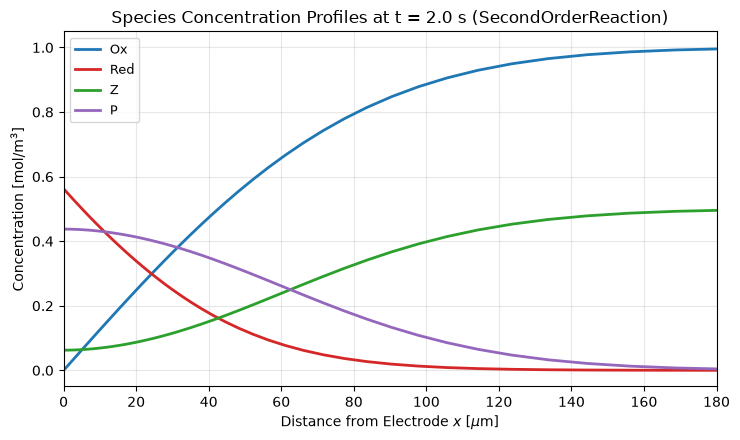

In [2]:
t_step = 2.0
mesh_2 = GeometricExpandingMesh.from_diffusion_layer(D=D, t_max=t_step, n_points=70, gamma=1.08)
t_eval_2 = np.linspace(0.0, t_step, 50)

ox2 = Species("Ox", diffusivity=D, bulk_concentration=1.0, standard_potential=0.0, n_electrons=1)
red2 = Species("Red", diffusivity=D, bulk_concentration=0.0)
z_scav = Species("Z", diffusivity=D, bulk_concentration=0.5)
p2 = Species("P", diffusivity=D, bulk_concentration=0.0)

mech_2nd = CustomMechanism(
    species=[ox2, red2, z_scav, p2],
    reactions=[SecondOrderReaction(red2, z_scav, p2, k=5.0)],
    electrochemical_steps=[
        ElectrochemicalStep(ox2, red2, ButlerVolmer(k0=1e-2, alpha=0.5, E0=0.0, n=1))
    ],
    name="EC2 Bimolecular Scavenging",
)

prob_2nd = mech_2nd.create_problem(mesh_2, potential=-0.35, geometry=geom)
res_2nd = solver.solve(prob_2nd, t_span=(0.0, t_step), t_eval=t_eval_2)
print(f"Second-order EC2 solve: success={res_2nd.success}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
x_um = mesh_2.nodes * 1e6
for sp_name, color in [("Ox", "tab:blue"), ("Red", "tab:red"), ("Z", "tab:green"), ("P", "tab:purple")]:
    ax.plot(x_um, res_2nd.concentrations[sp_name][-1], color=color, lw=2, label=sp_name)

ax.set_xlim(0, 180)
ax.set_xlabel(r"Distance from Electrode $x$ [$\mu$m]")
ax.set_ylabel(r"Concentration [$\mathrm{mol/m^3}$]")
ax.set_title(f"Species Concentration Profiles at t = {t_step} s (SecondOrderReaction)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Key Takeaways

- `Species`, `ElectrochemicalStep`, `FirstOrderReaction`, and `SecondOrderReaction` compose cleanly inside `CustomMechanism`.
- `mech.create_problem(...)` builds a complete multi-species `DiffusionProblem` with automated boundary conditions and analytical reaction Jacobians for stiff ODE/DAE solvers (`BDF` / `Radau`).